# Market Map — data pipeline

Two maps of the S&P 500:
- **Behaviour map**: stocks placed by how their prices move together *after removing the market*.
- **Business map**: stocks placed by text embeddings of their company descriptions.

The interesting part is where the two disagree. Output: `market_map.json` for the Next.js front end.

**Run:** Runtime → Run all. The first run takes about 8 minutes, mostly the ~500 description calls in step 6. Those are cached in `desc_cache.json`. Upload that file before running, or set `USE_DRIVE = True`, and later runs skip the calls.

## 0. Setup

In [1]:
%pip install -q yfinance umap-learn sentence-transformers lxml
import json, os, re, sys, time, warnings
from io import StringIO
import numpy as np, pandas as pd, requests, yfinance as yf, umap

SEED, PERIOD = 42, "2y"
OUT, CACHE = "market_map.json", "desc_cache.json"
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False   # True = keep the description cache on Google Drive so it survives runtime resets
if USE_DRIVE and IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/market_map", exist_ok=True)
    CACHE = "/content/drive/MyDrive/market_map/desc_cache.json"
for msg in [".*n_jobs value.*", ".*compatibility_layout.*", "using precomputed metric.*"]:
    warnings.filterwarnings("ignore", message=msg)   # known-harmless UMAP notices
pd.set_option("display.width", 160)

## 1. Universe: the S&P 500 list
Tickers, names and sectors come from Wikipedia. Yahoo writes BRK.B as BRK-B, so the dot becomes a dash.
*Caveat:* this is today's membership only (survivorship bias). That's fine for a map but not for a backtest.

In [2]:
html = requests.get("https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
                    headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
meta = pd.read_html(StringIO(html))[0][["Symbol", "Security", "GICS Sector", "GICS Sub-Industry"]]
meta["Symbol"] = meta["Symbol"].str.replace(".", "-", regex=False)
meta = meta.set_index("Symbol")
print(len(meta), "members,", meta["GICS Sector"].nunique(), "sectors")

503 members, 11 sectors


## 2. Prices
The tickers are downloaded in chunks of 100, because one giant request tends to fail. Each chunk retries with backoff if Yahoo rate-limits.

In [3]:
def download(chunk, tries=3):
    for k in range(tries):
        try:
            df = yf.download(chunk, period=PERIOD, auto_adjust=True, progress=False)["Close"]
            if not df.dropna(how="all").empty:
                return df
        except Exception as e:
            print(f"chunk starting {chunk[0]}: {type(e).__name__}, retrying")
        time.sleep(10 * (k + 1))
    raise RuntimeError(f"price download failed for chunk starting {chunk[0]}")

tickers = list(meta.index) + ["SPY"]
px = pd.concat([download(tickers[i:i + 100]) for i in range(0, len(tickers), 100)], axis=1)
assert "SPY" in px.columns and px["SPY"].notna().mean() > 0.99, "SPY missing: the market regression in step 4 needs it"
print(px.shape)

(501, 504)


## 3. Clean and convert to log returns
- Drop any stock missing more than 10% of days (recent IPOs, bad data).
- Forward-fill gaps of up to 3 days, then drop any rows that are still incomplete.

The row drop applies to every stock. A stock that listed partway through the window (but missed less than 10% of days) shortens the window for all of them. This cell prints the real date range, and the JSON exports it as `start`.

In [4]:
keep = px.notna().mean() > 0.9
print(f"dropped {(~keep).sum()} tickers with >10% missing: {sorted(px.columns[~keep])}")
px = px.loc[:, keep].ffill(limit=3)
late, n0 = list(px.columns[px.isna().any()]), len(px)
px = px.dropna()
print(f"rows dropped as incomplete: {n0 - len(px)} of {n0}" + (f" (caused by {late})" if late else ""))
rets = np.log(px).diff().dropna()
mkt = rets.pop("SPY")
print(f"{rets.shape[1]} stocks x {len(rets)} days, {rets.index[0].date()} to {rets.index[-1].date()}")

dropped 5 tickers with >10% missing: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
rows dropped as incomplete: 0 of 501
498 stocks x 500 days, 2024-11-20 to 2026-11-18


## 4. Strip out the market (the step that matters most)
Most of any stock's daily move is just "the market went up or down." Leave that in and every stock looks correlated with every other, so the map turns into one blob. Regress each stock on SPY and keep only what's left over:

$$r_i = \alpha_i + \beta_i \, r_m + \varepsilon_i \qquad \beta_i = \frac{\text{Cov}(r_i, r_m)}{\text{Var}(r_m)}$$

The residuals $\varepsilon_i$ are the stock's own behaviour.

In [5]:
X = np.column_stack([np.ones(len(mkt)), mkt.values])
coef, *_ = np.linalg.lstsq(X, rets.values, rcond=None)
resid = pd.DataFrame(rets.values - X @ coef, index=rets.index, columns=rets.columns)
beta = pd.Series(coef[1], index=rets.columns)

off = lambda C: C.values[np.triu_indices(len(C), 1)]          # upper-triangle pairs, no diagonal
r2 = 1 - resid.var() / rets.var()
print(f"median beta {beta.median():.2f}; the market explains {r2.median():.0%} of the median stock's daily variance")
print(f"mean pairwise correlation: raw {off(rets.corr()).mean():.3f} -> residual {off(resid.corr()).mean():.3f}")

median beta 0.71; the market explains 14% of the median stock's daily variance


mean pairwise correlation: raw 0.203 -> residual 0.082


## 5. Behaviour map
Turn the correlations into a proper distance. Two identical stocks get distance 0; perfectly opposite stocks get the maximum distance of 2.

$$d_{ij} = \sqrt{2\,(1 - \rho_{ij})}$$

In [6]:
def corr_map(C, seed=SEED, k=15):
    D = np.sqrt(2 * (1 - C.clip(-1, 1)))
    return umap.UMAP(metric="precomputed", n_neighbors=k, min_dist=0.1,
                     random_state=seed).fit_transform(D.values)

corr = resid.corr()
beh = corr_map(corr)
if {"NVDA", "AMD"} <= set(corr.index):
    rho = corr.loc["NVDA", "AMD"]
    print(f"worked example: NVDA-AMD residual rho = {rho:.2f} -> d = {np.sqrt(2 * (1 - rho)):.2f}")

worked example: NVDA-AMD residual rho = 0.18 -> d = 1.28


## 6. Business map
- Each company's description comes from yfinance. That's ~500 calls, so results are cached to `CACHE` and only missing ones are fetched. Failed calls are stored as `null` and retried next run. Empty descriptions are stored as `""` and not retried.
- If a description is missing, it falls back to the name plus the sub-industry.
- **Text cleanup (not in the original brief):** each company's own name and the "incorporated in… / headquartered in…" sentences are removed before embedding. Without this, the top "lookalike that trades apart" was Constellation Energy vs Constellation Brands (CEG/STZ), which are similar only because they share a name.
- The text is embedded locally with all-MiniLM-L6-v2 (free, no API), on CPU, so the same text always gives the same embedding.
- **Centering:** subtract the mean embedding, then renormalise. Every description shares boilerplate ("together with its subsidiaries", lists of regions), and centering removes that shared direction. On the 2026-11 run, sector purity of the business neighbours went 0.64 (raw) → 0.70 (cleaned) → 0.72 (cleaned + centered).

In [7]:
from sentence_transformers import SentenceTransformer

def save_cache():
    with open(CACHE, "w") as f: json.dump(desc, f)

def fetch_desc(t, tries=3):
    for k in range(tries):
        try:
            return yf.Ticker(t).info.get("longBusinessSummary") or ""
        except Exception as e:
            if k == tries - 1:
                print(f"\n{t}: {type(e).__name__}, will retry next run"); return None
            time.sleep(5 * 3 ** k)                              # 5s, then 15s: rides out short rate limits

desc = json.load(open(CACHE)) if os.path.exists(CACHE) else {}
todo = [t for t in corr.index if desc.get(t) is None]
print(f"fetching {len(todo)} descriptions ({len(corr) - len(todo)} cached)")
for n, t in enumerate(todo, 1):
    desc[t] = fetch_desc(t); time.sleep(0.2)
    if n % 50 == 0 or n == len(todo):
        save_cache(); print(n, end=" ", flush=True)

BOILER = re.compile(r"[^.]*\b(incorporated|founded|headquartered|formerly known as|changed its name)\b[^.]*\.\s*", re.I)
SUFFIX = re.compile(r"\s*\(.*?\)|,?\s+(Inc\.?|Corp\.?|Corporation|Company|Co\.|plc|Ltd\.?|Limited|Holdings?|Group|N\.V\.|The)$", re.I)
def core_name(n):                       # "Constellation Brands, Inc." -> "Constellation Brands"
    prev = None
    while prev != n: prev, n = n, SUFFIX.sub("", n).strip(" ,")
    return n
def clean(t, n):
    t, c = BOILER.sub("", t), core_name(n)
    for w in sorted({c, c.split()[0]}, key=len, reverse=True):   # full name first, then its first word
        if len(w) >= 3: t = re.sub(rf"\b{re.escape(w)}\b", "The company", t)
    return t

text = [clean(desc[t], meta.loc[t, "Security"]) if desc.get(t)
        else f"{meta.loc[t, 'Security']}: {meta.loc[t, 'GICS Sub-Industry']}" for t in corr.index]
fallback = [t for t in corr.index if not desc.get(t)]
print(f"\n{len(fallback)} on the name + sub-industry fallback: {fallback}")

model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
n_cut = sum(len(model.tokenizer(s)["input_ids"]) > model.max_seq_length for s in text)
print(f"{n_cut} of {len(text)} descriptions exceed {model.max_seq_length} tokens; only their opening is embedded")
emb = model.encode(text, normalize_embeddings=True, show_progress_bar=False).astype(np.float64)
emb -= emb.mean(0); emb /= np.linalg.norm(emb, axis=1, keepdims=True)   # centre: strip shared boilerplate direction
sim = emb @ emb.T                            # cosine similarity; float64 so the exported values round cleanly
biz = umap.UMAP(metric="cosine", n_neighbors=15, min_dist=0.1,
                random_state=SEED).fit_transform(emb)

fetching 0 descriptions (498 cached)



1 on the name + sub-industry fallback: ['FISV']


245 of 498 descriptions exceed 256 tokens; only their opening is embedded


## 7. Line the two maps up
UMAP's rotation is arbitrary. Without this step, toggling between the maps in the app spins everything randomly. Procrustes rotates (and if needed mirrors) the business map to best match the behaviour map, so only the stocks that genuinely moved appear to move.

Both maps are then divided by the same number, so together they fit in [-1, 1] and stay aligned.

*Limit:* Procrustes fixes rotation and mirroring only. UMAP places clusters relative to each other arbitrarily, so whole clusters can still slide when the app toggles. In a test, the 2-D distance each stock moved ranked whole clusters (all the utilities, all the semis) as the "biggest movers". UMAP is deterministic for identical input, but Yahoo's prices shift slightly between downloads (one correlation moved 0.448 → 0.449), and that's enough to change the layout. The neighbour lists and pair lists did not change between runs. For that reason, divergence is measured in the original correlation and similarity space (step 8), not on the 2-D maps.

In [8]:
from scipy.linalg import orthogonal_procrustes
norm = lambda a: (a - a.mean(0)) / np.abs(a - a.mean(0)).max()
beh, biz = norm(beh.astype(np.float64)), norm(biz.astype(np.float64))
R, _ = orthogonal_procrustes(biz, beh); biz = biz @ R
s = max(np.abs(beh).max(), np.abs(biz).max()); beh, biz = beh / s, biz / s

## 8. Divergence lists
- **Lookalikes that trade apart:** of the top 1% most similar businesses, the pairs with the lowest correlation. Out of sample (`oos_test.ipynb`), these pairs do re-couple: next-year correlation is +0.08 above matched controls. The catch-up trade, however, has no edge (+0.8%/yr, t 0.1), and with 1-year formation windows it loses (−8.8%/yr, t −2.7). Read this list as a risk signal (*likely to re-couple*), not a mispricing.
- **Hidden twins:** of the top 1% most correlated pairs, the ones with the least similar businesses. These point to shared exposure (rates, China, AI capex) that the descriptions don't mention. Out of sample, they keep ~70% of their excess correlation the next year (obvious twins keep ~97%), so most of it is a real, persistent exposure.
- **Per-stock `overlap` (added):** of a stock's 10 most correlated stocks, the share that are also among its 10 most similar businesses. 0 means it trades with a completely different crowd from the companies it resembles.

In [9]:
iu = np.triu_indices(len(corr), 1)
pairs = pd.DataFrame({"a": corr.index[iu[0]], "b": corr.index[iu[1]],
                      "corr": corr.values[iu], "sim": sim[iu]})
apart  = pairs[pairs.sim > pairs.sim.quantile(.99)].nsmallest(25, "corr")
hidden = pairs[pairs["corr"] > pairs["corr"].quantile(.99)].nsmallest(25, "sim")
print(f"top-1% cut-offs: sim > {pairs.sim.quantile(.99):.3f}, corr > {pairs['corr'].quantile(.99):.3f}")

name = meta["Security"]
show = lambda d: d.assign(a_name=name[d.a].values, b_name=name[d.b].values).round(3).to_string(index=False)
print("\nLOOKALIKES THAT TRADE APART\n" + show(apart))
print("\nHIDDEN TWINS\n" + show(hidden))

K = 10
def topk(M, k=K):
    M = M.copy(); np.fill_diagonal(M, -np.inf); return np.argsort(-M, axis=1)[:, :k]
nb_beh, nb_biz = topk(corr.values), topk(sim)
overlap = pd.Series([len(set(a) & set(b)) / K for a, b in zip(nb_beh, nb_biz)], index=corr.index)
strength = pd.Series(np.take_along_axis(corr.values, nb_beh[:, :3], 1).mean(1), index=corr.index)
print(f"\nOVERLAP@{K}: median {overlap.median():.1f}; {(overlap == 0).sum()} stocks share none of their top-{K} lists")
low = pd.DataFrame({"name": name[corr.index].values, "overlap": overlap, "corr_top3": strength.round(2),
                    "trades_with": [", ".join(corr.index[nb_beh[i, :3]]) for i in range(len(corr))],
                    "reads_like": [", ".join(corr.index[nb_biz[i, :3]]) for i in range(len(corr))]}, index=corr.index)
print(low.sort_values(["overlap", "corr_top3"], ascending=[True, False]).head(15).to_string())

top-1% cut-offs: sim > 0.445, corr > 0.513

LOOKALIKES THAT TRADE APART
   a    b   corr   sim                     a_name                  b_name
   D  GEV -0.216 0.453            Dominion Energy              GE Vernova
 GEV   SO -0.181 0.466                 GE Vernova        Southern Company
 DUK  GEV -0.180 0.585                Duke Energy              GE Vernova
 CEG   ED -0.118 0.481       Constellation Energy     Consolidated Edison
 AEP  GEV -0.118 0.496    American Electric Power              GE Vernova
   D  VST -0.108 0.576            Dominion Energy            Vistra Corp.
ECHO   VZ -0.101 0.487                   EchoStar                 Verizon
   T ECHO -0.096 0.495                       AT&T                EchoStar
CTSH  ROK -0.093 0.490                  Cognizant     Rockwell Automation
 DUK  VST -0.092 0.505                Duke Energy            Vistra Corp.
EVRG  GEV -0.089 0.570                     Evergy              GE Vernova
 CEG    D -0.075 0.502       Constellati

## 9. Export for the front end
One JSON file for Next.js. Values are rounded to 3 dp. The coordinates are cast to float64 first: UMAP returns float32, and a rounded float32 `0.629` comes out of JSON as `0.6290000081062317` (186 KB vs 160 KB for the whole file). `allow_nan=False` makes a bad value fail here instead of breaking `JSON.parse` in the browser.

In [10]:
def nn(M, i, k=5):
    o = np.argsort(-M[i]); o = o[o != i][:k]
    return [[corr.index[j], round(float(M[i, j]), 3)] for j in o]
r3 = lambda v: [round(float(x), 3) for x in v]

out = {"asof": str(rets.index[-1].date()), "start": str(rets.index[0].date()), "window": PERIOD, "days": len(rets),
       "stocks": [{"t": t, "name": meta.loc[t, "Security"], "sector": meta.loc[t, "GICS Sector"],
                   "sub": meta.loc[t, "GICS Sub-Industry"], "beh": r3(beh[i]), "biz": r3(biz[i]),
                   "overlap": float(overlap[t]), "beta": round(float(beta[t]), 2),
                   "nnBeh": nn(corr.values, i), "nnBiz": nn(sim, i)}
                  for i, t in enumerate(corr.index)],
       "apart": apart.round(3).to_dict("records"), "hidden": hidden.round(3).to_dict("records")}
with open(OUT, "w") as f:
    json.dump(out, f, separators=(",", ":"), allow_nan=False)
print(f"{OUT}: {os.path.getsize(OUT) / 1024:.0f} KB, {len(out['stocks'])} stocks, {out['start']} to {out['asof']}")
if IN_COLAB:
    from google.colab import files; files.download(OUT)

market_map.json: 160 KB, 498 stocks, 2024-11-20 to 2026-11-18


## 10. Sanity checks before you trust it
Each check from the brief is turned into a number:
- **Sector purity:** the share of each stock's 10 nearest neighbours on the map that are in its own GICS sector. Random placement scores the "chance" line. The behaviour map should be far above chance. The same map built *without* step 4 should score lower; that's the one-blob test.
- **Neighbours:** JPM should sit near BAC and C, and XOM near CVX. PASS needs each expected name in the stock's top 10 by residual correlation *and* within its 20 nearest points on the map. Within a dense cluster (Energy has 21 stocks with purity 0.96), the 2-D order of the top 10 shifts between runs.
- **Seed stability:** rebuild with other seeds. If purity drops or neighbourhoods change a lot, raise `n_neighbors` to 30.
- **Residual correlations:** within a sector, expect lots of 0.2–0.4. Above 0.6 is a genuinely strong link.

In [11]:
from sklearn.neighbors import NearestNeighbors
sector = meta.loc[corr.index, "GICS Sector"].to_numpy(dtype=object)

def knn(Y, k=10):
    return NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y, return_distance=False)[:, 1:]
def purity(Y, k=10):
    return (sector[knn(Y, k)] == sector[:, None]).mean()

raw = norm(corr_map(rets.corr()).astype(np.float64))         # same pipeline, step 4 skipped
chance = (pd.Series(sector).value_counts(normalize=True) ** 2).sum()
print(f"sector purity of 10 nearest neighbours (chance = {chance:.2f})")
for label, Y in [("behaviour, market removed", beh), ("behaviour, raw returns", raw), ("business", biz)]:
    print(f"  {label:<27} {purity(Y):.2f}")

sector purity of 10 nearest neighbours (chance = 0.11)
  behaviour, market removed   0.72
  behaviour, raw returns      0.68
  business                    0.73


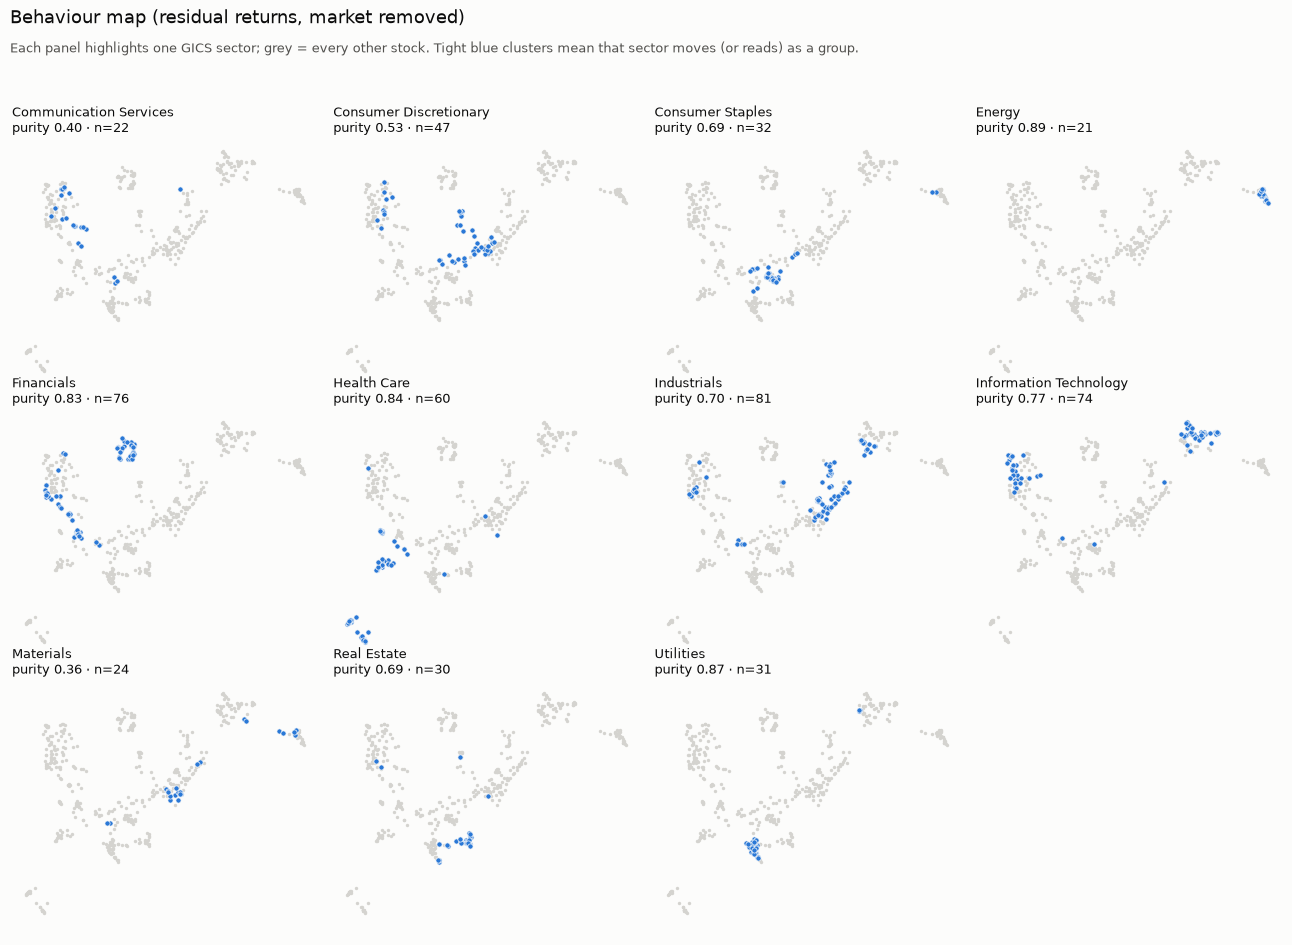

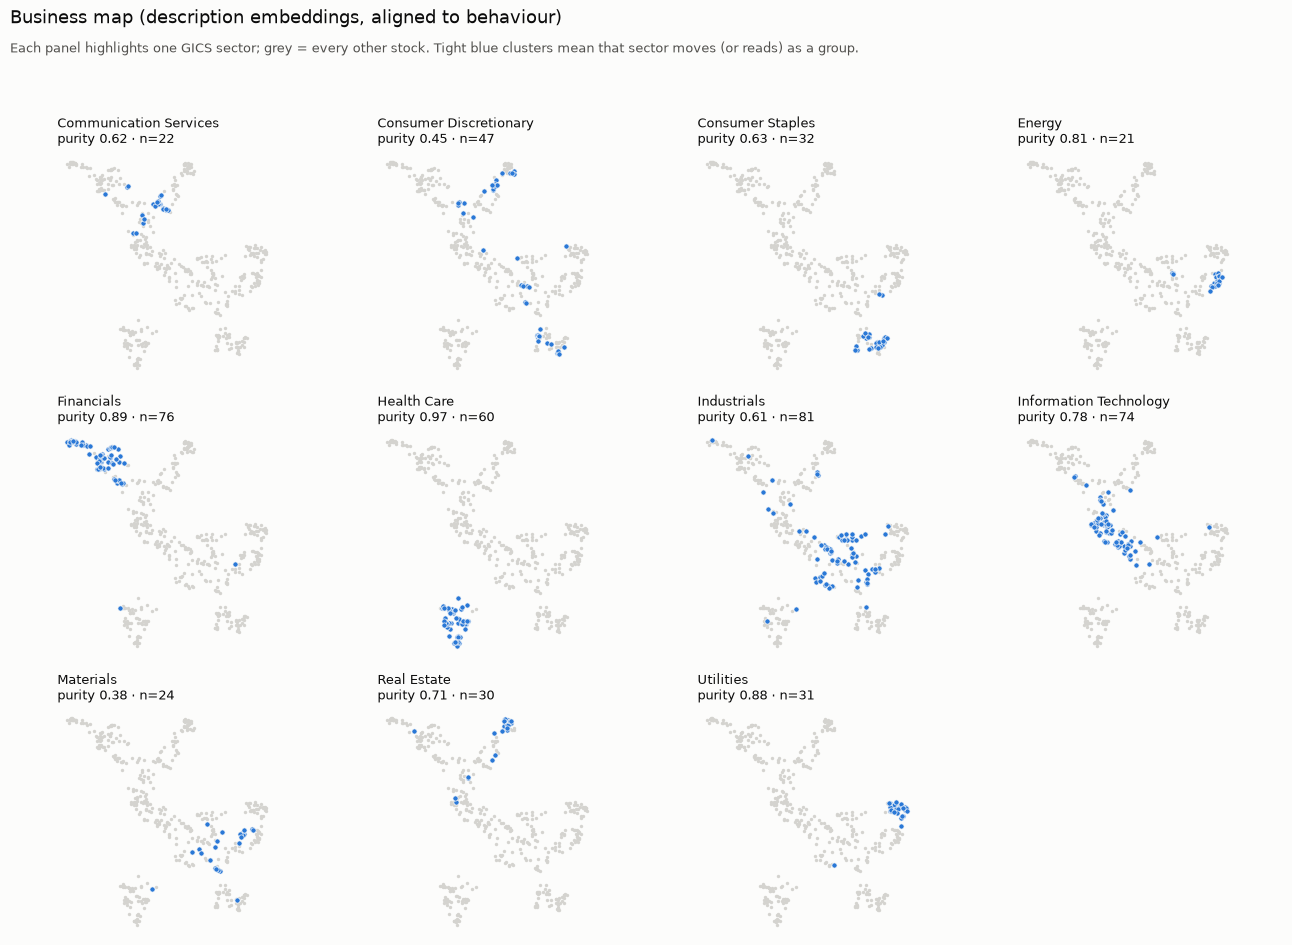

In [12]:
import matplotlib.pyplot as plt
SURFACE, INK, INK2, HIGHLIGHT, REST = "#fcfcfb", "#0b0b0b", "#52514e", "#2a78d6", "#d4d3cf"
sectors = sorted(set(sector))

def facet(Y, title):
    fig, axes = plt.subplots(3, 4, figsize=(13, 9.6), facecolor=SURFACE)
    nbr = knn(Y)
    for ax in axes.flat: ax.set_axis_off(); ax.set_facecolor(SURFACE)
    for ax, sec in zip(axes.flat, sectors):
        m = sector == sec
        p = (sector[nbr[m]] == sec).mean()
        ax.scatter(*Y[~m].T, s=6, c=REST, linewidths=0)
        ax.scatter(*Y[m].T, s=14, c=HIGHLIGHT, edgecolors=SURFACE, linewidths=0.5)
        ax.set_title(f"{sec}\npurity {p:.2f} · n={m.sum()}", fontsize=9, color=INK, loc="left")
        ax.set_aspect("equal")
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, color=INK)
    fig.text(0.01, 0.935, "Each panel highlights one GICS sector; grey = every other stock. "
             "Tight blue clusters mean that sector moves (or reads) as a group.", fontsize=9, color=INK2)
    fig.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

facet(beh, "Behaviour map (residual returns, market removed)")
facet(biz, "Business map (description embeddings, aligned to behaviour)")

In [13]:
pos_nbrs = knn(beh, 20)
idx = {t: i for i, t in enumerate(corr.index)}
for t, want in {"JPM": ["BAC", "C"], "XOM": ["CVX"], "NVDA": []}.items():   # NVDA: no expectation, just look
    if t not in idx: continue
    top_corr = list(corr[t].drop(t).nlargest(10).index)
    on_map = [corr.index[j] for j in pos_nbrs[idx[t]]]
    ok = all(w in top_corr and w in on_map for w in want if w in idx)
    print(f"{'INFO' if not want else 'PASS' if ok else 'WARN'} {t}: want {want} | top-5 by residual corr "
          f"{[(n, round(float(corr.loc[t, n]), 2)) for n in top_corr[:5]]} | nearest on map {on_map[:5]}")

PASS JPM: want ['BAC', 'C'] | top-5 by residual corr [('BAC', 0.64), ('WFC', 0.62), ('C', 0.55), ('MS', 0.54), ('GS', 0.51)] | nearest on map ['GS', 'C', 'BAC', 'NTRS', 'WFC']
PASS XOM: want ['CVX'] | top-5 by residual corr [('CVX', 0.86), ('COP', 0.83), ('EOG', 0.8), ('DVN', 0.78), ('OXY', 0.78)] | nearest on map ['APA', 'EOG', 'FANG', 'BKR', 'COP']
INFO NVDA: want [] | top-5 by residual corr [('VRT', 0.44), ('VST', 0.39), ('GEV', 0.36), ('FIX', 0.33), ('SMCI', 0.32)] | nearest on map ['ANET', 'AVGO', 'ORCL', 'BE', 'CEG']


In [14]:
base = knn(beh)
print(f"seed stability vs seed {SEED} (overlap = mean share of each stock's 10 map neighbours kept)")
for seed in [0, 1, 2]:
    Y = norm(corr_map(corr, seed=seed).astype(np.float64))
    overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(base, knn(Y))])
    print(f"  seed {seed}: purity {purity(Y):.2f}, neighbour overlap {overlap:.2f}")

seed stability vs seed 42 (overlap = mean share of each stock's 10 map neighbours kept)


  seed 0: purity 0.72, neighbour overlap 0.74


  seed 1: purity 0.73, neighbour overlap 0.74


  seed 2: purity 0.72, neighbour overlap 0.73


In [15]:
same = sector[:, None] == sector[None, :]
rc, sc = corr.values[iu], same[iu]
q = lambda v: " / ".join(f"{x:.2f}" for x in np.percentile(v, [10, 50, 90]))
print(f"residual corr p10 / p50 / p90  within sector: {q(rc[sc])}   across sectors: {q(rc[~sc])}")
for lo, hi in [(0.2, 0.4), (0.4, 0.6), (0.6, 1.01)]:
    m = (rc >= lo) & (rc < hi)
    print(f"  {lo:.1f}-{min(hi, 1):.1f}: {m.sum():>6} pairs ({m.mean():.1%} of all), {sc[m].mean():.0%} of them same-sector")

residual corr p10 / p50 / p90  within sector: -0.06 / 0.19 / 0.47   across sectors: -0.13 / 0.07 / 0.26
  0.2-0.4:  23532 pairs (19.0% of all), 19% of them same-sector
  0.4-0.6:   3032 pairs (2.5% of all), 48% of them same-sector
  0.6-1.0:    637 pairs (0.5% of all), 96% of them same-sector


## Caveats
- **Survivorship:** the universe is today's members. Fine for a map, not for a backtest.
- **In-sample:** every number here describes the same 2-year window it was measured on. `oos_test.ipynb` runs the out-of-sample test over 7 rolling folds (2016–2026). The divergence lists predict future *co-movement* (a small effect, likely overstated because it uses today's descriptions). They don't predict *prices*: the lookalike catch-up trade fails.
- **Text artefacts:** stocks on the name + sub-industry fallback have short, templated text. They can look similar to each other just because the text is short, so check the fallback list printed in step 6 before trusting a pair that includes one of them.

## JSON shape (for the Next.js side)
```ts
type Pair = { a: string; b: string; corr: number; sim: number };
type Stock = {
  t: string; name: string; sector: string; sub: string;
  beh: [number, number]; biz: [number, number];   // aligned, both inside [-1, 1]
  overlap: number;                                 // share of top-10 behaviour neighbours that are also top-10 business neighbours
  beta: number;
  nnBeh: [string, number][];                       // top-5 by residual correlation
  nnBiz: [string, number][];                       // top-5 by description cosine similarity
};
type MarketMap = { asof: string; start: string; window: string; days: number;
                   stocks: Stock[]; apart: Pair[]; hidden: Pair[] };
```